# Fit the plate-position correction

Wells in a given row and column of a plate are shifted in a consistent, feature-specific direction (a "tilt") that is unrelated to what is in the well (see `0.diagnose_position_effect.ipynb`).
For example, the first principal component of the wells falls from row B to row G, among the wells of one cell type as well (see the diagnostics).

This notebook **estimates** that tilt from the normalized single-cell profiles of the five validation plates and writes the result to this folder.
It does not change any existing profiles.
Applying the correction is a separate step: `../4b.apply_position_correction.ipynb` reads the saved fit (`position_correction_fit.npz`).
Rerun this notebook whenever the normalized profiles change.
Delete `well_medians.parquet` first so that the notebook rebuilds the well medians from the new profiles instead of reading the cache.

**Layout.** Every plate has 60 wells (rows B to G, columns 2 to 11), in blocks of columns: the failing DMSO (18 wells) in columns 2, 4, and 10 and the healthy DMSO (18 wells) in columns 3, 9, and 11, in all six rows at the same positions on all five plates, and 24 compound wells in columns 5 to 8, in all six rows. Each plate has three compounds with eight wells each, in positions that differ between plates (15 compounds in all, on failing cells).

**Method (details in `../../../utils/validation_position_utils.py`, which builds on the screen's `../../../utils/position_correction_utils.py`):**

1. Summarize each well as the median profile of its cells.
2. Average the five replicate plates of each position of the DMSO wells (the compound wells are on one plate each).
3. Fit a row plus column effect per feature, together with one effect for each group of wells (the healthy DMSO, the failing DMSO, and each compound) ("tilt map").
   The screen places every compound once and relies on compounds averaging out over 11 platemaps.
   Here every group sits at several positions, so the fit can tell the effect of the group from the effect of the position.
   The controls enter the fit because they give the replicates at identical positions on all five plates.
   Because the groups sit in blocks of columns, a group effect can absorb the offset of its block, so three column offsets (failing, healthy, compounds) cannot be told from the group effects.
   The fit does not split them arbitrarily: the column effects have no reference column and a tiny ridge penalty, which sets what the data cannot determine to zero, so the difference between the healthy and the failing controls stays in the group effects.
4. Measure the amplitude of each plate, the scale of the tilt that best matches the plate, and shrink it toward the average of the other plates, as the screen does for its platemaps.
5. A cell is corrected by subtracting the amplitude of its plate times the tilt of its well from its features.

**Output** (in this folder)

- `position_correction_fit.npz`: the tilt map and the amplitude of each plate (keyed by the plate number, 1 to 5), in the format that step 4b reads.
- `results/plate_amplitudes.csv`: how strongly the tilt shows in each replicate plate, before and after shrinking.
- `figures/fit/tilt_size_and_amplitudes.png`

## Import libraries

In [1]:
import os
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../../../utils")
import position_correction_utils as pcu
import validation_position_utils as vpu

## Set paths and variables

In [2]:
# folder with the <plate>_sc_normalized.parquet files (only read when the cache is missing)
profile_dir = pathlib.Path(
    os.environ.get(
        "VALIDATION_PROFILE_DIR",
        "~/mnt/bandicoot/CFReT_screening_data/validation_profiles/single_cell_profiles",
    )
).expanduser()
n_jobs = int(os.environ.get("N_JOBS", "4"))

output_dir = pathlib.Path(".")
figure_dir = output_dir / "figures" / "fit"
figure_dir.mkdir(parents=True, exist_ok=True)
results_dir = output_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# well-level summary is cached because reading the five plates takes a few minutes
well_medians_cache = output_dir / "well_medians.parquet"

min_cells = 50  # minimum cells for a well to be used (as in the screen)

## Summarize every well

Each well becomes the median profile of its normalized cells.
Features with a missing value in any well cannot be modeled and are dropped.

In [3]:
well_medians, features = vpu.load_or_build_well_medians(
    well_medians_cache, profile_dir, n_jobs=n_jobs
)

print("Plates:", well_medians["plate"].nunique())
print("Wells:", len(well_medians))
print("Features:", len(features))

Plates: 5
Wells: 300
Features: 2453


## Fit the tilt map

The fit uses the 15 compounds and both kinds of DMSO, each at several positions.
Its coefficients are the effects of rows C to G relative to row B and of columns 3 to 11 relative to column 2, for every feature (`vpu.fit_compound_adjusted_tilt`).

In [4]:
tilt_map = vpu.fit_compound_adjusted_tilt(
    well_medians, features, min_cells, include_controls=True
)
print("Tilt map:", tilt_map["coef"].shape[0], "row and column terms for", len(features), "features")

Tilt map: 15 row and column terms for 2453 features


The amplitude of a plate is the scale of the tilt that best matches its wells, after the mean of each group of wells (the healthy DMSO, the failing DMSO, or a compound) is removed (1 means the tilt at its estimated strength), and the error bar is its standard error from resampling the wells.
The tilt was fit on all five plates, so the amplitudes should be around 1.
A plate far from 1 means that the position effect is not the same on every plate.
Like the screen, we shrink the amplitude of each plate toward the average of the other four (`shrunk_amplitude`), and the correction uses the shrunk amplitude.

In [5]:
amplitudes = vpu.shrunk_plate_amplitudes(well_medians, tilt_map, min_cells)
fit = vpu.with_plate_amplitudes(tilt_map, amplitudes)
pcu.save_fit(fit, output_dir / "position_correction_fit.npz")
print("Amplitude of each plate:", fit["amplitudes"])
amplitudes.to_csv(results_dir / "plate_amplitudes.csv", index=False)
amplitudes.round(3)

Amplitude of each plate: {1: 1.050907157423678, 2: 0.9206859977549837, 3: 0.9214871525126132, 4: 0.9497407534636622, 5: 0.8214808321766457}


,plate,plate_number,amplitude,standard_error,shrunk_amplitude
0,CARD-CelIns-CX7_261030160001,1,1.102,0.053,1.051
1,CARD-CelIns-CX7_261031160001,2,0.921,0.050,0.921
2,CARD-CelIns-CX7_261101160003,3,0.922,0.063,0.921
3,CARD-CelIns-CX7_261102080001,4,0.957,0.067,0.950
4,CARD-CelIns-CX7_261102150001,5,0.705,0.054,0.821


## How large is the tilt, and how strongly does it apply to each plate?

Left: the size of the tilt at each well position (root mean square over features, in normalized units).
Right: the amplitude of each replicate plate.

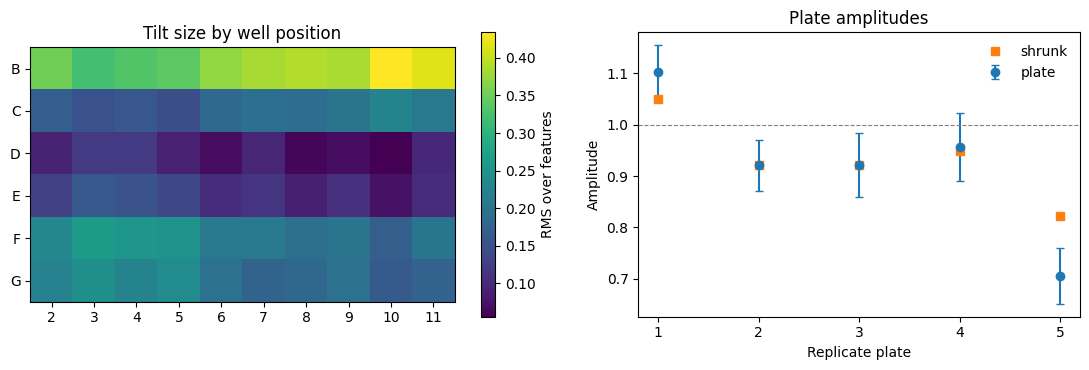

In [6]:
grid_rows, grid_cols = np.meshgrid(range(6), range(10), indexing="ij")
tilt_grid = pcu.tilt(
    fit["coef"], fit["center"], grid_rows.ravel(), grid_cols.ravel()
).reshape(6, 10, -1)
tilt_size = np.sqrt((tilt_grid**2).mean(axis=2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
image = axes[0].imshow(tilt_size, cmap="viridis")
axes[0].set_xticks(range(10), labels=range(2, 12))
axes[0].set_yticks(range(6), labels=list(pcu.ROWS))
axes[0].set_title("Tilt size by well position")
fig.colorbar(image, ax=axes[0], label="RMS over features")

axes[1].errorbar(
    amplitudes["plate_number"],
    amplitudes["amplitude"],
    yerr=amplitudes["standard_error"],
    fmt="o",
    label="plate",
    capsize=3,
)
axes[1].plot(
    amplitudes["plate_number"], amplitudes["shrunk_amplitude"], "s", label="shrunk"
)
axes[1].legend(frameon=False)
axes[1].axhline(1, color="grey", lw=0.8, ls="--")
axes[1].set_xticks(amplitudes["plate_number"], labels=amplitudes["plate_number"])
axes[1].set_xlabel("Replicate plate")
axes[1].set_ylabel("Amplitude")
axes[1].set_title("Plate amplitudes")
fig.tight_layout()
fig.savefig(figure_dir / "tilt_size_and_amplitudes.png", dpi=120)
plt.show()

The tilt is estimated from the compound wells and both kinds of DMSO wells, and it is subtracted from every well.
The healthy and the failing DMSO wells are in blocks of columns that cover all six rows evenly, so the correction should leave the healthy minus failing contrast as it is (the ratio of its length after and before is near 1).

In [7]:
wells = well_medians[well_medians["n"] >= min_cells].reset_index(drop=True)
wells["row"], wells["col"] = pcu.well_index(wells["well"])
offsets = wells["platemap"].map(fit["amplitudes"]).to_numpy()[:, None] * pcu.tilt(
    fit["coef"], fit["center"], wells["row"].to_numpy(), wells["col"].to_numpy()
)

is_dmso = wells["treatment"] == "DMSO"
kind = np.where(
    is_dmso & (wells["cell_type"] == vpu.HEALTHY_CELL_TYPE),
    "healthy DMSO",
    np.where(is_dmso & (wells["cell_type"] == vpu.FAILING_CELL_TYPE), "failing DMSO", "compound"),
)
offset_size = pd.Series(np.sqrt((offsets**2).mean(axis=1)), name="mean offset (RMS)")
print(offset_size.groupby(kind).agg(["mean", "size"]).round(3))

contrast = vpu.control_contrast(wells, features).merge(
    vpu.control_contrast(wells, features, offsets),
    on="plate",
    suffixes=("_raw", "_corrected"),
)
contrast["ratio"] = contrast["norm_corrected"] / contrast["norm_raw"]
contrast.round(2).to_csv(results_dir / "control_contrast.csv", index=False)
print(contrast.round(2).to_string(index=False))
print(
    f"\nHealthy minus failing DMSO contrast over {len(contrast)} plates: "
    f"median norm ratio (corrected / raw) {contrast['ratio'].median():.2f}"
)

               mean  size
compound      0.179   120
failing DMSO  0.184    90
healthy DMSO  0.187    90


                       plate  norm_raw  norm_corrected  ratio
CARD-CelIns-CX7_261030160001     12.92           12.92    1.0
CARD-CelIns-CX7_261031160001     14.55           14.55    1.0
CARD-CelIns-CX7_261101160003     12.82           12.82    1.0
CARD-CelIns-CX7_261102080001     13.76           13.76    1.0
CARD-CelIns-CX7_261102150001     12.97           12.97    1.0

Healthy minus failing DMSO contrast over 5 plates: median norm ratio (corrected / raw) 1.00


## Assumptions and limits

- **Additive and shared shape.** Position adds a fixed vector to every cell in a well, the same for every group of wells and for both cell types.
  The tilt has one row term and one column term per feature, with no interaction of row and column.
- **Group effects.** The fit gives every group of wells its own effect, so what all wells of a group share does not enter the tilt.
  The fit has 32 parameters per feature (17 groups, 5 row terms, 10 column terms with a ridge penalty) for 156 averaged wells.
  Three column offsets (the failing DMSO columns, the healthy DMSO columns, the compound columns) cannot be told from the group effects, so the column terms are the part of the column effect that differs within each block, and the ridge sets the rest to zero.
  `2.validate_position_correction.ipynb` tests the fit on held-out plates.
- **Healthy and failing cells have the same tilt.** The correction assumes position moves healthy and failing cells equally.
  Both cell types sit at many positions, so this can be tested: `5.quantify_position_effect.ipynb` fits the tilt on the failing DMSO and predicts the healthy DMSO.
- **The number of cells.** Part of the position effect works through the number of cells in the well (`0.diagnose_position_effect.ipynb`).
  The tilt is a function of the position only, so the correction removes that part as position.
- **Features with missing values** are dropped and cannot be corrected.
- The fit here uses every plate, so it cannot show that the correction works.
  See `2.validate_position_correction.ipynb` for held-out validation.